<a href="https://colab.research.google.com/github/nour2344/RoadAnomaly-DeepLearning/blob/main/notebooks/03_cnn_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Modelling : CNN Baseline

## 1. Chargement des données

Nous commençons par entraîner un CNN simple pour la segmentation sémantique des anomalies routières.

Ce premier modèle servira de référence (baseline) pour comparer les architectures plus avancées.

Nous réutilisons les mêmes ensembles Train, Validation et Test définis dans la Data Preparation, sans refaire le split.

In [1]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import torch

# Monter Google Drive
drive.mount("/content/drive")

# Chemins
PROJECT_DIR = Path("/content/drive/MyDrive/deep learning P")
SPLIT_PATH = PROJECT_DIR / "split_manifest.csv"

# Charger le split existant
df = pd.read_csv(SPLIT_PATH)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "validation"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

# Vérification
print("Train :", len(train_df))
print("Validation :", len(val_df))
print("Test :", len(test_df))

print("GPU disponible :", torch.cuda.is_available())
print("Device :", "cuda" if torch.cuda.is_available() else "cpu")

assert len(train_df) == 42
assert len(val_df) == 9
assert len(test_df) == 9

Mounted at /content/drive
Train : 42
Validation : 9
Test : 9
GPU disponible : True
Device : cuda


## 2. Préparation des données pour le CNN

Nous réutilisons le prétraitement défini dans le Notebook 02 :

- Images redimensionnées à 256 × 256 avec padding.
- Pixels normalisés entre 0 et 1.
- Masques binaires : 0 (normal), 1 (anomalie).
- Augmentation uniquement pour le Train.

Les DataLoaders fournissent les images et leurs masques par batches de 4.

In [2]:
import numpy as np
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader

IMG_SIZE = (256, 256)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def preprocess_image(path):
    image = Image.open(path).convert("RGB")
    image = ImageOps.pad(
        image, IMG_SIZE,
        method=Image.Resampling.BILINEAR,
        color=(0, 0, 0)
    )
    return np.asarray(image, dtype=np.float32) / 255.0

def preprocess_mask(path):
    mask = Image.open(path).convert("L")
    mask = ImageOps.pad(
        mask, IMG_SIZE,
        method=Image.Resampling.NEAREST,
        color=0
    )
    return (np.asarray(mask) == 2).astype(np.float32)

def augment_image_mask(image, mask, rng):
    if rng.random() < 0.5:
        image = np.flip(image, axis=1).copy()
        mask = np.flip(mask, axis=1).copy()

    image = np.clip(image * rng.uniform(0.8, 1.2), 0, 1)
    mean = image.mean(axis=(0, 1), keepdims=True)
    image = np.clip(
        (image - mean) * rng.uniform(0.8, 1.2) + mean, 0, 1
    )
    return image.astype(np.float32), mask

class RoadAnomalyDataset(Dataset):
    def __init__(self, dataframe, augment=False):
        self.data = dataframe.reset_index(drop=True)
        self.augment = augment
        self.rng = np.random.default_rng(42)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        image = preprocess_image(row["image"])
        mask = preprocess_mask(row["mask"])

        if self.augment:
            image, mask = augment_image_mask(image, mask, self.rng)

        image = torch.from_numpy(
            np.ascontiguousarray(image.transpose(2, 0, 1))
        ).float()

        mask = torch.from_numpy(
            np.ascontiguousarray(mask[None, :, :])
        ).float()

        return image, mask

train_loader = DataLoader(
    RoadAnomalyDataset(train_df, augment=True),
    batch_size=4, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    RoadAnomalyDataset(val_df),
    batch_size=4, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    RoadAnomalyDataset(test_df),
    batch_size=4, shuffle=False, num_workers=0
)

images, masks = next(iter(train_loader))

print("Images :", images.shape)
print("Masques :", masks.shape)
print("Device :", device)

Images : torch.Size([4, 3, 256, 256])
Masques : torch.Size([4, 1, 256, 256])
Device : cuda


## 3. Construction du CNN Baseline

Nous construisons un CNN simple avec un encodeur et un décodeur.

- **Encodeur :** extrait les caractéristiques des images grâce aux convolutions et au pooling.
- **Décodeur :** agrandit les cartes de caractéristiques pour retrouver la taille de l'image.
- **Sortie :** un score par pixel permettant de prédire les anomalies.

Ce modèle servira de référence pour comparer les architectures plus avancées.

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Encodeur
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        # Décodeur
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 1, kernel_size=1)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x


# Créer le modèle sur le GPU
model = SimpleCNN().to(device)

# Vérification sur un batch
images, masks = next(iter(train_loader))

with torch.no_grad():
    outputs = model(images.to(device))

print("Entrée :", images.shape)
print("Sortie :", outputs.shape)
print("Masques réels :", masks.shape)

print("Nombre de paramètres :",
      sum(p.numel() for p in model.parameters()))

Entrée : torch.Size([4, 3, 256, 256])
Sortie : torch.Size([4, 1, 256, 256])
Masques réels : torch.Size([4, 1, 256, 256])
Nombre de paramètres : 33889


## 4. Fonction de perte et optimiseur

Nous utilisons une combinaison de BCE Loss et Dice Loss pour entraîner notre CNN.

- **BCE Loss :** mesure les erreurs de prédiction des pixels.
- **Dice Loss :** aide à mieux segmenter les anomalies malgré le déséquilibre des classes.
- **Adam :** optimise les paramètres du modèle avec un learning rate de 0.001.

Nous combinerons les deux pertes avec le même poids.

In [4]:
import torch
import torch.nn as nn

# BCE Loss
bce_loss = nn.BCEWithLogitsLoss()

# Dice Loss
def dice_loss(logits, targets, smooth=1.0):
    probs = torch.sigmoid(logits)

    intersection = (probs * targets).sum(dim=(1, 2, 3))
    union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + smooth) / (union + smooth)

    return 1 - dice.mean()


# Combinaison des deux pertes
def combined_loss(logits, targets):
    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return 0.5 * bce + 0.5 * dice


# Optimiseur
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Vérification sur un batch
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

outputs = model(images)

loss = combined_loss(outputs, masks)

print("BCE Loss :", round(bce_loss(outputs, masks).item(), 4))
print("Dice Loss :", round(dice_loss(outputs, masks).item(), 4))
print("Combined Loss :", round(loss.item(), 4))
print("Optimizer : Adam")
print("Learning rate :", optimizer.param_groups[0]["lr"])

BCE Loss : 0.8025
Dice Loss : 0.872
Combined Loss : 0.8373
Optimizer : Adam
Learning rate : 0.001


## 5. Entraînement et validation du CNN

Nous entraînons notre CNN sur les 42 images d'entraînement et évaluons sa perte sur les 9 images de validation.

- **Epochs :** maximum 30 passages sur les données d'entraînement.
- **Batch size :** 4 images.
- **Early Stopping :** arrêt après 6 époques sans amélioration de la Validation Loss.
- **Model Checkpoint :** sauvegarde du modèle ayant obtenu la meilleure Validation Loss.

Nous suivons les pertes Train et Validation pour observer l'apprentissage et détecter un éventuel surapprentissage.

In [5]:
import torch
from pathlib import Path

EPOCHS = 30
PATIENCE = 6

best_val_loss = float("inf")
patience_counter = 0

train_losses = []
val_losses = []

# Dossier de sauvegarde
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "cnn_baseline_best.pth"

for epoch in range(EPOCHS):

    # -------- TRAINING --------
    model.train()
    train_loss = 0.0

    for images, masks in train_loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)

    # -------- VALIDATION --------
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)
            loss = combined_loss(outputs, masks)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_loader.dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # -------- SAVE BEST MODEL --------
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        patience_counter = 0

        torch.save(model.state_dict(), MODEL_PATH)

    else:
        patience_counter += 1

    # -------- EARLY STOPPING --------
    if patience_counter >= PATIENCE:
        print("\nEarly Stopping activated.")
        break

print("\nTraining completed!")
print("Best Validation Loss :", round(best_val_loss, 4))
print("Model saved at :", MODEL_PATH)

Epoch 01/30 | Train Loss: 0.8508 | Val Loss: 0.8411
Epoch 02/30 | Train Loss: 0.8250 | Val Loss: 0.7734
Epoch 03/30 | Train Loss: 0.7269 | Val Loss: 0.6752
Epoch 04/30 | Train Loss: 0.6676 | Val Loss: 0.6430
Epoch 05/30 | Train Loss: 0.6359 | Val Loss: 0.6058
Epoch 06/30 | Train Loss: 0.5980 | Val Loss: 0.5701
Epoch 07/30 | Train Loss: 0.5745 | Val Loss: 0.5608
Epoch 08/30 | Train Loss: 0.5687 | Val Loss: 0.5545
Epoch 09/30 | Train Loss: 0.5619 | Val Loss: 0.5505
Epoch 10/30 | Train Loss: 0.5602 | Val Loss: 0.5441
Epoch 11/30 | Train Loss: 0.5557 | Val Loss: 0.5415
Epoch 12/30 | Train Loss: 0.5487 | Val Loss: 0.5383
Epoch 13/30 | Train Loss: 0.5450 | Val Loss: 0.5355
Epoch 14/30 | Train Loss: 0.5409 | Val Loss: 0.5341
Epoch 15/30 | Train Loss: 0.5404 | Val Loss: 0.5365
Epoch 16/30 | Train Loss: 0.5299 | Val Loss: 0.5442
Epoch 17/30 | Train Loss: 0.5345 | Val Loss: 0.5297
Epoch 18/30 | Train Loss: 0.5427 | Val Loss: 0.5304
Epoch 19/30 | Train Loss: 0.5285 | Val Loss: 0.5160
Epoch 20/30 

## 6. Analyse des courbes d'apprentissage

Nous comparons la Train Loss et la Validation Loss pour vérifier si le modèle apprend correctement et repérer un éventuel surapprentissage.

Le meilleur modèle est celui de l'époque 28, avec une Validation Loss de 0.4783.

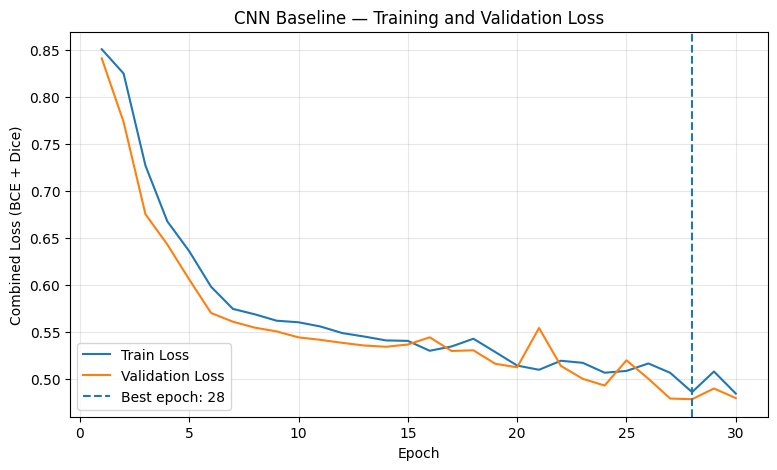

Best epoch: 28
Best Validation Loss: 0.4783


In [6]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, len(train_losses) + 1)
best_epoch = int(np.argmin(val_losses)) + 1

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Combined Loss (BCE + Dice)")
plt.title("CNN Baseline — Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Best epoch: {best_epoch}")
print(f"Best Validation Loss: {min(val_losses):.4f}")

## 7. Évaluation du CNN

Nous évaluons le meilleur CNN sur les 9 images de test.

Nous utilisons quatre métriques : IoU, Dice, Precision et Recall.

Les prédictions sont transformées en masques binaires avec un seuil de 0.5. Les résultats permettront de comparer ce CNN aux autres architectures.

In [7]:
# Charger le meilleur CNN sauvegardé
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

TP = FP = FN = 0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        # Prédiction
        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = probs >= 0.5

        targets = masks >= 0.5

        TP += (preds & targets).sum().item()
        FP += (preds & ~targets).sum().item()
        FN += (~preds & targets).sum().item()

# Métriques sur tous les pixels du test
eps = 1e-7

iou = TP / (TP + FP + FN + eps)
dice = 2 * TP / (2 * TP + FP + FN + eps)
precision = TP / (TP + FP + eps)
recall = TP / (TP + FN + eps)

print("CNN Baseline — Test Results")
print(f"IoU       : {iou:.4f}")
print(f"Dice      : {dice:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")

CNN Baseline — Test Results
IoU       : 0.1925
Dice      : 0.3229
Precision : 0.4104
Recall    : 0.2661


## 8. Visualisation des prédictions

Nous comparons les images originales, les masques réels et les masques prédits par le CNN.

Cette visualisation permet d'identifier les anomalies détectées et celles que le modèle manque.

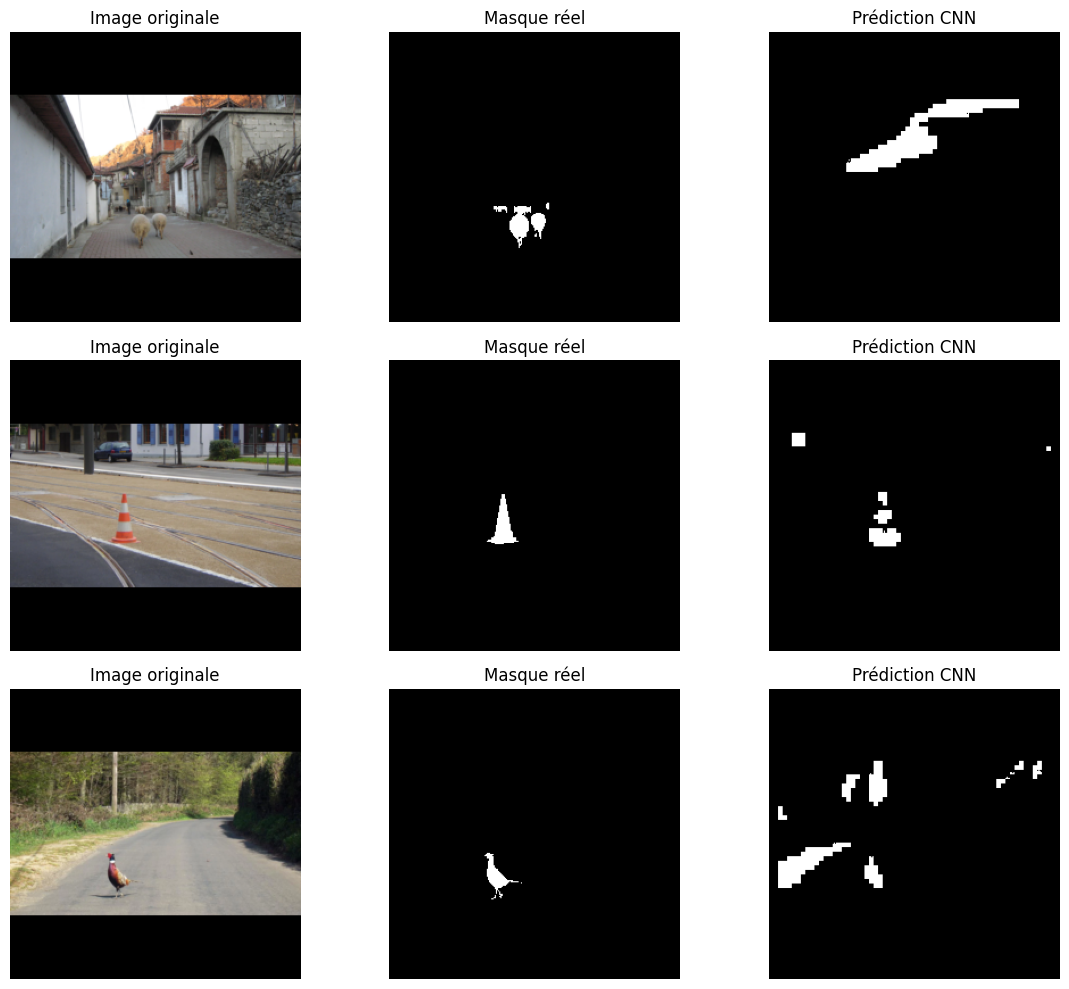

In [9]:
import matplotlib.pyplot as plt
import torch

# Charger le meilleur modèle
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.eval()

# Récupérer le Dataset depuis le DataLoader existant
test_dataset = test_loader.dataset

# Visualiser 3 images du Test
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

with torch.no_grad():
    for i in range(3):
        image, mask = test_dataset[i]

        logits = model(image.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits) >= 0.5)

        image_np = image.permute(1, 2, 0).cpu().numpy()
        mask_np = mask.squeeze().cpu().numpy()
        pred_np = pred.squeeze().cpu().numpy()

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title("Image originale")

        axes[i, 1].imshow(mask_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Masque réel")

        axes[i, 2].imshow(pred_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Prédiction CNN")

        for ax in axes[i]:
            ax.axis("off")

plt.tight_layout()
plt.show()

## 9. Conclusion

Le CNN Baseline a été entraîné pendant 30 époques. Le meilleur modèle a été obtenu à l'époque 28.

Sur les 9 images de test, les résultats sont :

| Métrique | Score |
|---|---|
| IoU | 0.1925 |
| Dice | 0.3229 |
| Precision | 0.4104 |
| Recall | 0.2661 |

Les résultats montrent que le CNN détecte certaines anomalies, mais manque de précision dans leur localisation et ne détecte qu'une partie des pixels anormaux.

Ce modèle servira de référence pour comparer les performances des architectures plus avancées, notamment U-Net et FCN.